[![Open In Colab](https://colab.research.google.com/assets/colab-badge.svg)](https://colab.research.google.com/github/phildani7/why-book-of-deep-learning-part-1/blob/main/notebooks/ch16_KidsLab05_CIFAR10_Layer_Visualization.ipynb)

**The Why Book of Deep Learning, Part 1** by Dr. Philemon Paul Daniel

**Chapter 16: Building Real CNNs: Fashion-MNIST and CIFAR-10** (Part III: Seeing). This lab comes from the simplified video course for kids, kept for comparison.

* Read this chapter free online: [www.micyaai.com/books/why-deep-learning-1/read.html?ch=16](https://www.micyaai.com/books/why-deep-learning-1/read.html?ch=16)
* The simplified video course for kids that this book grew from: [aikids.guru](https://www.aikids.guru)
* All the notebooks for the book: [github.com/phildani7/why-book-of-deep-learning-part-1](https://github.com/phildani7/why-book-of-deep-learning-part-1)

Tested with TensorFlow 2.21 and Keras 3.14. In Colab: *Runtime > Run all*. A GPU runtime makes the bigger
models faster but none of them needs one.

---


# 🎨 CIFAR-10 CNN: See Inside the AI Brain!
## Visualize Every Layer + Upload YOUR Photos!

**What you'll learn:**
1. Explore CIFAR-10 colorful images
2. Build a CNN step-by-step
3. **SEE what each layer learns!**
4. Train the network
5. Upload photos and classify!

**10 Categories:**
✈️ Airplane | 🚗 Automobile | 🐦 Bird | 🐱 Cat | 🦌 Deer  
🐕 Dog | 🐸 Frog | 🐴 Horse | 🚢 Ship | 🚚 Truck

---

> ### ✅ Checked edition (November 2026)
> This notebook was re-run top to bottom and checked for *The Why Book of Deep Learning, Part 1*. What changed from the original:
>
> * **Fixed the crash.** Building the layer-viewing models in Cell 9 failed with *"The layer CIFAR10_CNN has never been called and thus has no defined input"*: in Keras 3, `model.input` is not defined for this `Sequential` model (not even after training). The model now starts with `keras.Input(shape=(32, 32, 3))`, and the three viewing models use `model.inputs` (plural), which works.
> * **Honest feature maps.** Every map had its own colour scale, so near-silent filters looked as bright as busy ones. Each figure now uses one shared scale.
> * Layer 3's printed claims ("some filters activate ONLY for cats", "only for vehicles", "complete object parts") were not shown by anything in the notebook; they are toned down to what the pictures can show, with a suggestion to check.
> * **Runs outside Colab**, with your own photos in `MY_IMAGES` or a demo photo; photos are cropped to a centred square before shrinking to 32×32. Plot titles show class names instead of emoji that Matplotlib cannot draw.
> * "Trained on 50,000 images" corrected to 40,000: `validation_split=0.2` keeps 10,000 for validation. `keras.utils.set_random_seed(42)` and one log line per epoch.

## 📦 Cell 1: Import Libraries

In [1]:
import numpy as np
import matplotlib.pyplot as plt
import cv2
import tensorflow as tf
from tensorflow import keras
from tensorflow.keras import layers, models
from tensorflow.keras.datasets import cifar10

keras.utils.set_random_seed(42)   # Python, NumPy and TensorFlow in one call: the same run every time

print("✅ Libraries loaded!")
print(f"TensorFlow: {tf.__version__}")

✅ Libraries loaded!
TensorFlow: 2.21.0


---
## 📊 Cell 2: Load CIFAR-10 Dataset

In [2]:
print("📥 Loading CIFAR-10 dataset...\n")

(X_train, y_train), (X_test, y_test) = cifar10.load_data()

# Class names and emojis
class_names = ['Airplane', 'Automobile', 'Bird', 'Cat', 'Deer',
               'Dog', 'Frog', 'Horse', 'Ship', 'Truck']
class_emojis = ['✈️', '🚗', '🐦', '🐱', '🦌', '🐕', '🐸', '🐴', '🚢', '🚚']

print(f"✅ CIFAR-10 loaded!")
print(f"Training images: {X_train.shape[0]:,}")
print(f"Test images: {X_test.shape[0]:,}")
print(f"Image size: {X_train.shape[1]}×{X_train.shape[2]}")
print(f"Color channels: {X_train.shape[3]} (RGB)")
print(f"\n🎨 Categories:")
for i, (emoji, name) in enumerate(zip(class_emojis, class_names)):
    print(f"  {emoji} {i}: {name}")

📥 Loading CIFAR-10 dataset...



✅ CIFAR-10 loaded!
Training images: 50,000
Test images: 10,000
Image size: 32×32
Color channels: 3 (RGB)

🎨 Categories:
  ✈️ 0: Airplane
  🚗 1: Automobile
  🐦 2: Bird
  🐱 3: Cat
  🦌 4: Deer
  🐕 5: Dog
  🐸 6: Frog
  🐴 7: Horse
  🚢 8: Ship
  🚚 9: Truck


---
## 🎨 Cell 3: Explore CIFAR-10 Images

🔍 Sample images from each category:



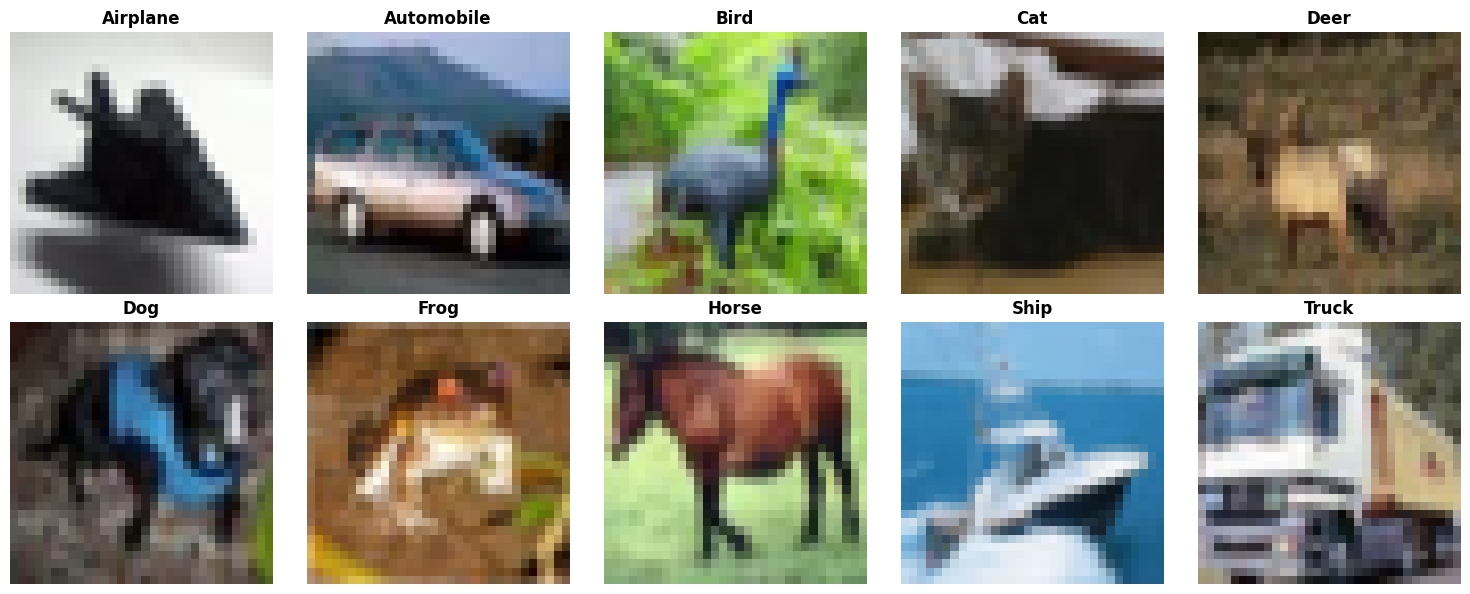


💡 Notice: These are 32×32 pixel images!
   Small but the CNN will learn to recognize them!


In [3]:
print("🔍 Sample images from each category:\n")

fig, axes = plt.subplots(2, 5, figsize=(15, 6))
axes = axes.ravel()

for i in range(10):
    # Find first image of each class
    idx = np.where(y_train == i)[0][0]
    axes[i].imshow(X_train[idx])
    axes[i].set_title(f"{class_names[i]}",
                      fontsize=12, fontweight='bold')
    axes[i].axis('off')

plt.tight_layout()
plt.show()

print("\n💡 Notice: These are 32×32 pixel images!")
print("   Small but the CNN will learn to recognize them!")

---
## 🔧 Cell 4: Preprocess Data

In [4]:
print("🔧 Preprocessing data...\n")

# Normalize: 0-255 → 0-1
X_train_norm = X_train.astype('float32') / 255.0
X_test_norm = X_test.astype('float32') / 255.0

# One-hot encode labels
y_train_cat = keras.utils.to_categorical(y_train, 10)
y_test_cat = keras.utils.to_categorical(y_test, 10)

print("✅ Preprocessing complete!")
print(f"\n📊 Shapes:")
print(f"  X_train: {X_train_norm.shape}")
print(f"  X_test: {X_test_norm.shape}")
print(f"  Pixel range: {X_train_norm.min():.1f} to {X_train_norm.max():.1f}")

🔧 Preprocessing data...



✅ Preprocessing complete!

📊 Shapes:
  X_train: (50000, 32, 32, 3)
  X_test: (10000, 32, 32, 3)
  Pixel range: 0.0 to 1.0


---
## 🏗️ Cell 5: Build CNN Architecture

**Our CNN has 3 main blocks:**
- **Block 1:** Learn basic features (edges, colors)
- **Block 2:** Learn patterns (textures, shapes)
- **Block 3:** Learn objects (complete features)

Each block has:
- Conv2D layers (learn features)
- MaxPooling (reduce size, keep important info)
- Dropout (prevent memorization)

In [5]:
print("🏗️ Building CNN...\n")

model = models.Sequential([
    # BLOCK 1: Basic Features (32 filters)
    keras.Input(shape=(32, 32, 3)),     # an explicit input: needed to look inside the layers later
    layers.Conv2D(32, (3, 3), activation='relu', padding='same', name='conv1_1'),
    layers.Conv2D(32, (3, 3), activation='relu', padding='same', name='conv1_2'),
    layers.MaxPooling2D((2, 2), name='pool1'),
    layers.Dropout(0.2, name='dropout1'),

    # BLOCK 2: Patterns (64 filters)
    layers.Conv2D(64, (3, 3), activation='relu', padding='same', name='conv2_1'),
    layers.Conv2D(64, (3, 3), activation='relu', padding='same', name='conv2_2'),
    layers.MaxPooling2D((2, 2), name='pool2'),
    layers.Dropout(0.3, name='dropout2'),

    # BLOCK 3: Objects (128 filters)
    layers.Conv2D(128, (3, 3), activation='relu', padding='same', name='conv3_1'),
    layers.Conv2D(128, (3, 3), activation='relu', padding='same', name='conv3_2'),
    layers.MaxPooling2D((2, 2), name='pool3'),
    layers.Dropout(0.4, name='dropout3'),

    # CLASSIFICATION LAYERS
    layers.Flatten(name='flatten'),
    layers.Dense(128, activation='relu', name='dense1'),
    layers.Dropout(0.5, name='dropout4'),
    layers.Dense(10, activation='softmax', name='output')
], name='CIFAR10_CNN')

model.compile(
    optimizer='adam',
    loss='categorical_crossentropy',
    metrics=['accuracy']
)

print("✅ CNN built!\n")
model.summary()

print("\n🧠 Architecture Breakdown:")
print("  Block 1 (32 filters): Edges, colors, simple shapes")
print("  Block 2 (64 filters): Textures, patterns, object parts")
print("  Block 3 (128 filters): Complete object features")
print("  Dense layers: Combine everything → classification")

🏗️ Building CNN...



✅ CNN built!



Model: "CIFAR10_CNN"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ conv1_1 (Conv2D)                │ (None, 32, 32, 32)     │           896 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv1_2 (Conv2D)                │ (None, 32, 32, 32)     │         9,248 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ pool1 (MaxPooling2D)            │ (None, 16, 16, 32)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout1 (Dropout)              │ (None, 16, 16, 32)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2_1 (Conv2D)                │ (None, 16, 16, 64)     │        18,496 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2_2 (Conv2D)                │ (None, 16, 16, 64)     │        36,928 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ pool2 (MaxPooling2D)            │ (None, 8, 8, 64)       │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout2 (Dropout)              │ (None, 8, 8, 64)       │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv3_1 (Conv2D)                │ (None, 8, 8, 128)      │        73,856 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv3_2 (Conv2D)                │ (None, 8, 8, 128)      │       147,584 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ pool3 (MaxPooling2D)            │ (None, 4, 4, 128)      │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout3 (Dropout)              │ (None, 4, 4, 128)      │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ flatten (Flatten)               │ (None, 2048)           │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense1 (Dense)                  │ (None, 128)            │       262,272 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout4 (Dropout)              │ (None, 128)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ output (Dense)                  │ (None, 10)             │         1,290 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 550,570 (2.10 MB)

 Trainable params: 550,570 (2.10 MB)

 Non-trainable params: 0 (0.00 B)


🧠 Architecture Breakdown:
  Block 1 (32 filters): Edges, colors, simple shapes
  Block 2 (64 filters): Textures, patterns, object parts
  Block 3 (128 filters): Complete object features
  Dense layers: Combine everything → classification


---
## 📐 Cell 6: Visualize CNN Architecture

See how the image size changes through each layer!

📐 Visualizing how image size changes...



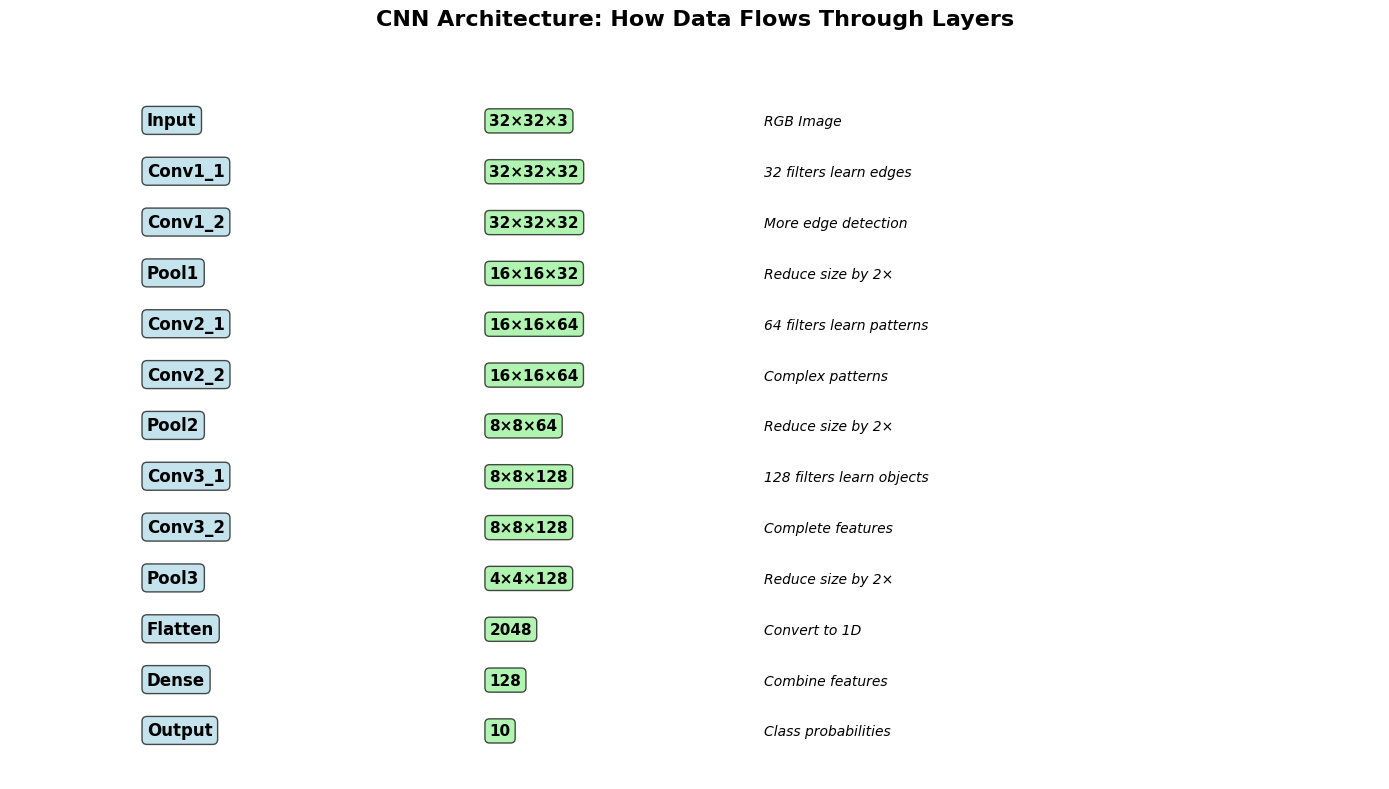


💡 Key Observations:
  • Image size DECREASES: 32×32 → 16×16 → 8×8 → 4×4
  • Number of filters INCREASES: 32 → 64 → 128
  • Features become more ABSTRACT and SPECIFIC
  • Final flatten converts 4×4×128 = 2,048 numbers


In [6]:
print("📐 Visualizing how image size changes...\n")

# Create a diagram showing dimension changes
fig, ax = plt.subplots(figsize=(14, 8))
ax.axis('off')

# Layer information
layers_info = [
    ("Input", "32×32×3", "RGB Image"),
    ("Conv1_1", "32×32×32", "32 filters learn edges"),
    ("Conv1_2", "32×32×32", "More edge detection"),
    ("Pool1", "16×16×32", "Reduce size by 2×"),
    ("Conv2_1", "16×16×64", "64 filters learn patterns"),
    ("Conv2_2", "16×16×64", "Complex patterns"),
    ("Pool2", "8×8×64", "Reduce size by 2×"),
    ("Conv3_1", "8×8×128", "128 filters learn objects"),
    ("Conv3_2", "8×8×128", "Complete features"),
    ("Pool3", "4×4×128", "Reduce size by 2×"),
    ("Flatten", "2048", "Convert to 1D"),
    ("Dense", "128", "Combine features"),
    ("Output", "10", "Class probabilities")
]

y_pos = 0.9
for name, shape, description in layers_info:
    # Layer name
    ax.text(0.1, y_pos, name, fontsize=12, fontweight='bold',
            bbox=dict(boxstyle='round', facecolor='lightblue', alpha=0.7))
    # Shape
    ax.text(0.35, y_pos, shape, fontsize=11, fontweight='bold',
            bbox=dict(boxstyle='round', facecolor='lightgreen', alpha=0.7))
    # Description
    ax.text(0.55, y_pos, description, fontsize=10, style='italic')

    y_pos -= 0.07

ax.set_xlim(0, 1)
ax.set_ylim(0, 1)
plt.title('CNN Architecture: How Data Flows Through Layers',
          fontsize=16, fontweight='bold', pad=20)
plt.tight_layout()
plt.show()

print("\n💡 Key Observations:")
print("  • Image size DECREASES: 32×32 → 16×16 → 8×8 → 4×4")
print("  • Number of filters INCREASES: 32 → 64 → 128")
print("  • Features become more ABSTRACT and SPECIFIC")
print("  • Final flatten converts 4×4×128 = 2,048 numbers")

---
## 🎯 Cell 7: Train the CNN! (50 Epochs)

⏰ Takes about 10-15 minutes on GPU

In [7]:
print("🎯 Training CNN for 50 epochs...\n")
print("⏰ This takes 10-15 minutes with GPU. Watch the progress!\n")

# Callbacks
early_stop = keras.callbacks.EarlyStopping(
    monitor='val_accuracy',
    patience=10,
    restore_best_weights=True
)

reduce_lr = keras.callbacks.ReduceLROnPlateau(
    monitor='val_loss',
    factor=0.5,
    patience=5,
    min_lr=0.00001
)

# Train
history = model.fit(
    X_train_norm, y_train_cat,
    epochs=50,
    batch_size=64,
    validation_split=0.2,
    callbacks=[early_stop, reduce_lr],
    verbose=2            # one line per epoch
)

print("\n✅ Training complete!")

🎯 Training CNN for 50 epochs...

⏰ This takes 10-15 minutes with GPU. Watch the progress!



Epoch 1/50


625/625 - 29s - 46ms/step - accuracy: 0.3261 - loss: 1.7966 - val_accuracy: 0.4819 - val_loss: 1.3996 - learning_rate: 0.0010


Epoch 2/50


625/625 - 25s - 41ms/step - accuracy: 0.4997 - loss: 1.3842 - val_accuracy: 0.5979 - val_loss: 1.1153 - learning_rate: 0.0010


Epoch 3/50


... (92 outputs left out)

625/625 - 24s - 38ms/step - accuracy: 0.8767 - loss: 0.3509 - val_accuracy: 0.8263 - val_loss: 0.5890 - learning_rate: 2.5000e-04


Epoch 50/50


625/625 - 24s - 38ms/step - accuracy: 0.8791 - loss: 0.3390 - val_accuracy: 0.8275 - val_loss: 0.5846 - learning_rate: 1.2500e-04



✅ Training complete!


---
## 📈 Cell 8: Training History

📈 Visualizing training progress...



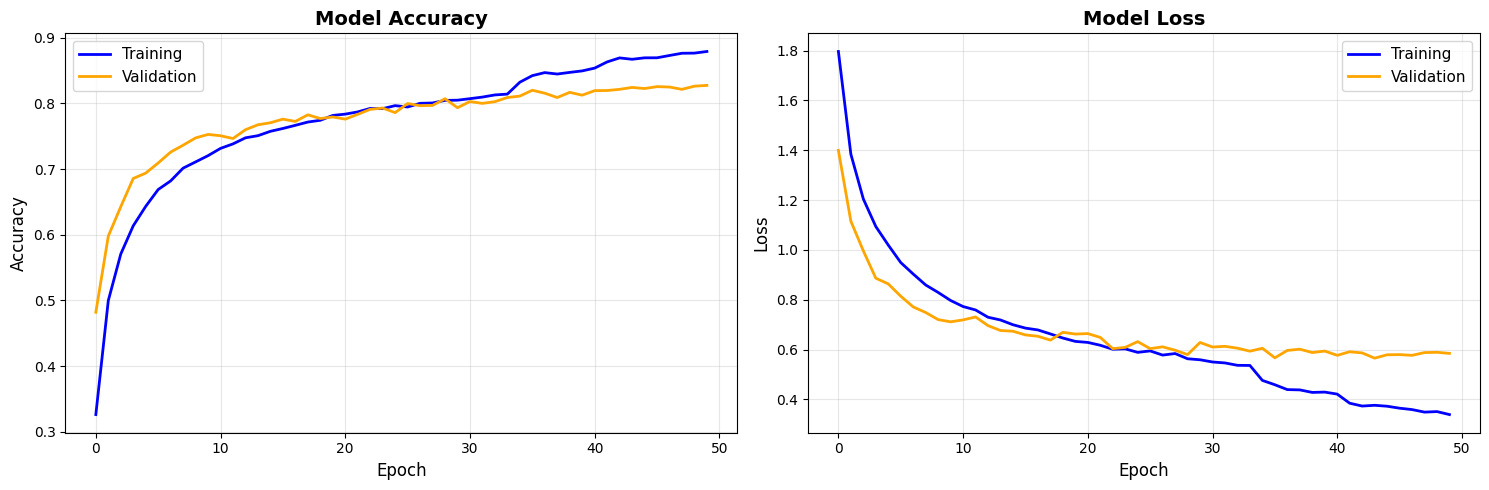


📊 Final Results:
  Training Accuracy: 87.91%
  Validation Accuracy: 82.75%


In [8]:
print("📈 Visualizing training progress...\n")

fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(15, 5))

# Accuracy
ax1.plot(history.history['accuracy'], label='Training', linewidth=2, color='blue')
ax1.plot(history.history['val_accuracy'], label='Validation', linewidth=2, color='orange')
ax1.set_xlabel('Epoch', fontsize=12)
ax1.set_ylabel('Accuracy', fontsize=12)
ax1.set_title('Model Accuracy', fontsize=14, fontweight='bold')
ax1.legend(fontsize=11)
ax1.grid(True, alpha=0.3)

# Loss
ax2.plot(history.history['loss'], label='Training', linewidth=2, color='blue')
ax2.plot(history.history['val_loss'], label='Validation', linewidth=2, color='orange')
ax2.set_xlabel('Epoch', fontsize=12)
ax2.set_ylabel('Loss', fontsize=12)
ax2.set_title('Model Loss', fontsize=14, fontweight='bold')
ax2.legend(fontsize=11)
ax2.grid(True, alpha=0.3)

plt.tight_layout()
plt.show()

print(f"\n📊 Final Results:")
print(f"  Training Accuracy: {history.history['accuracy'][-1]*100:.2f}%")
print(f"  Validation Accuracy: {history.history['val_accuracy'][-1]*100:.2f}%")

> **Reading the feature maps below:** within one figure every map uses the **same colour scale**, from 0
> (dark) to the strongest response of any map in the figure (bright). A filter that hardly reacts to this image
> really does look dark. (With a separate scale per map, a filter answering 0.01 would look as bright as one
> answering 5, and every filter would seem equally busy.)

---
## 🔬 Cell 9: VISUALIZE LAYER 1 - What Does It See?

**Layer 1 (conv1_1): Basic Features**
- Learns: Edges, lines, colors
- 32 different filters
- Each filter looks for something specific!

🔬 Visualizing Layer 1: Basic Features

Test image: 🦌 Deer



Layer 1 output shape: (1, 32, 32, 32)
  → 32×32 image, 32 different filters



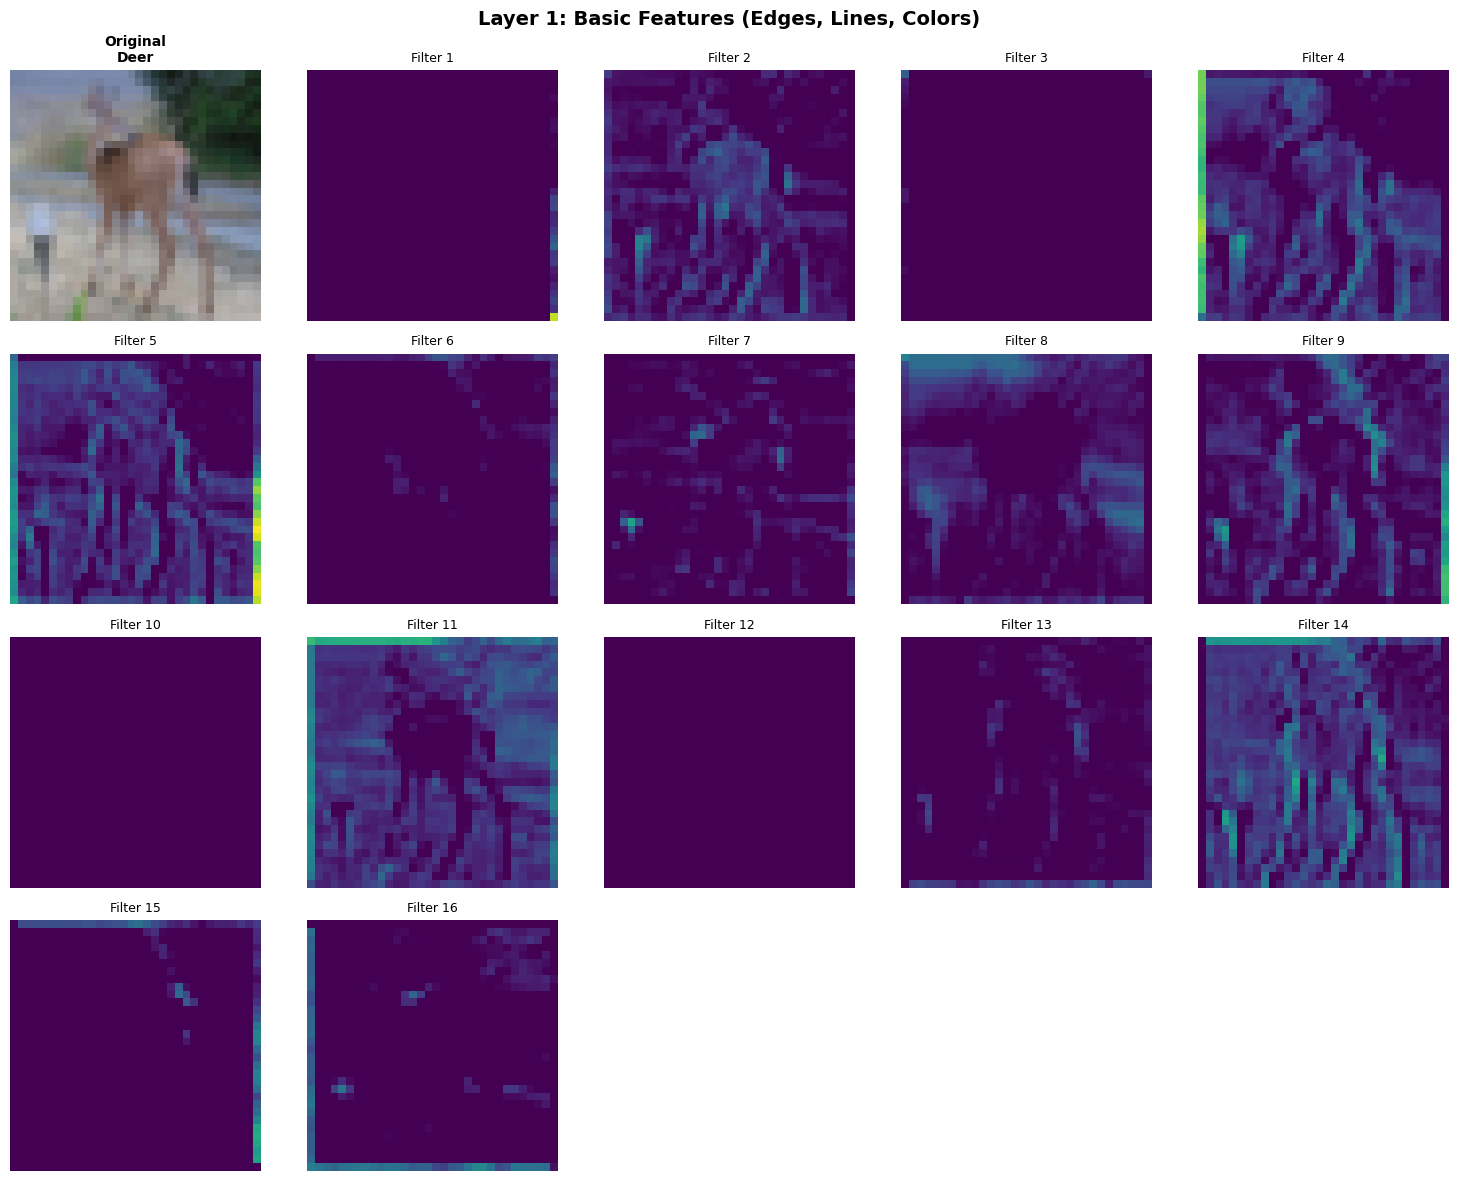


💡 WHAT TO OBSERVE:
  • Different filters activate on different features
  • Some filters detect HORIZONTAL edges
  • Some filters detect VERTICAL edges
  • Some filters detect DIAGONAL edges
  • Some filters detect COLOR differences
  • Brighter areas = filter strongly activated
  • Darker areas = filter not activated

🎯 TRY THIS:
  Change 'test_idx' to see different images!
  Try: 0, 50, 100, 500, 1000
  Compare how filters respond to different objects!


In [9]:
print("🔬 Visualizing Layer 1: Basic Features\n")

# Pick a test image
test_idx = 100
test_image = X_test_norm[test_idx:test_idx+1]
test_label = class_names[y_test[test_idx][0]]

print(f"Test image: {class_emojis[y_test[test_idx][0]]} {test_label}\n")

# Create model to get layer 1 output
layer1_model = models.Model(
    inputs=model.inputs,   # .inputs, not .input (Keras 3)
    outputs=model.get_layer('conv1_1').output
)

# Get activations
layer1_output = layer1_model.predict(test_image, verbose=0)

print(f"Layer 1 output shape: {layer1_output.shape}")
print(f"  → 32×32 image, 32 different filters\n")

# Plot original image and first 16 filters
fig, axes = plt.subplots(4, 5, figsize=(15, 12))
axes = axes.ravel()

# Original image
axes[0].imshow(X_test[test_idx])
axes[0].set_title(f"Original\n{test_label}", fontweight='bold', fontsize=10)
axes[0].axis('off')

# First 16 filters
vmax = layer1_output[0, :, :, :16].max()   # ONE colour scale for every map in this figure
for i in range(16):
    axes[i+1].imshow(layer1_output[0, :, :, i], cmap='viridis', vmin=0, vmax=vmax)
    axes[i+1].set_title(f"Filter {i+1}", fontsize=9)
    axes[i+1].axis('off')

# Hide remaining subplots
for i in range(17, 20):
    axes[i].axis('off')

plt.suptitle('Layer 1: Basic Features (Edges, Lines, Colors)',
             fontsize=14, fontweight='bold')
plt.tight_layout()
plt.show()

print("\n💡 WHAT TO OBSERVE:")
print("  • Different filters activate on different features")
print("  • Some filters detect HORIZONTAL edges")
print("  • Some filters detect VERTICAL edges")
print("  • Some filters detect DIAGONAL edges")
print("  • Some filters detect COLOR differences")
print("  • Brighter areas = filter strongly activated")
print("  • Darker areas = filter not activated")

print("\n🎯 TRY THIS:")
print("  Change 'test_idx' to see different images!")
print("  Try: 0, 50, 100, 500, 1000")
print("  Compare how filters respond to different objects!")

---
## 🔬 Cell 10: VISUALIZE LAYER 2 - Patterns Emerge!

**Layer 2 (conv2_1): Patterns & Textures**
- Learns: Combinations of edges
- Textures, shapes, object parts
- 64 filters (more complex!)

🔬 Visualizing Layer 2: Patterns & Textures

Layer 2 output shape: (1, 16, 16, 64)
  → 16×16 image (pooled), 64 different filters



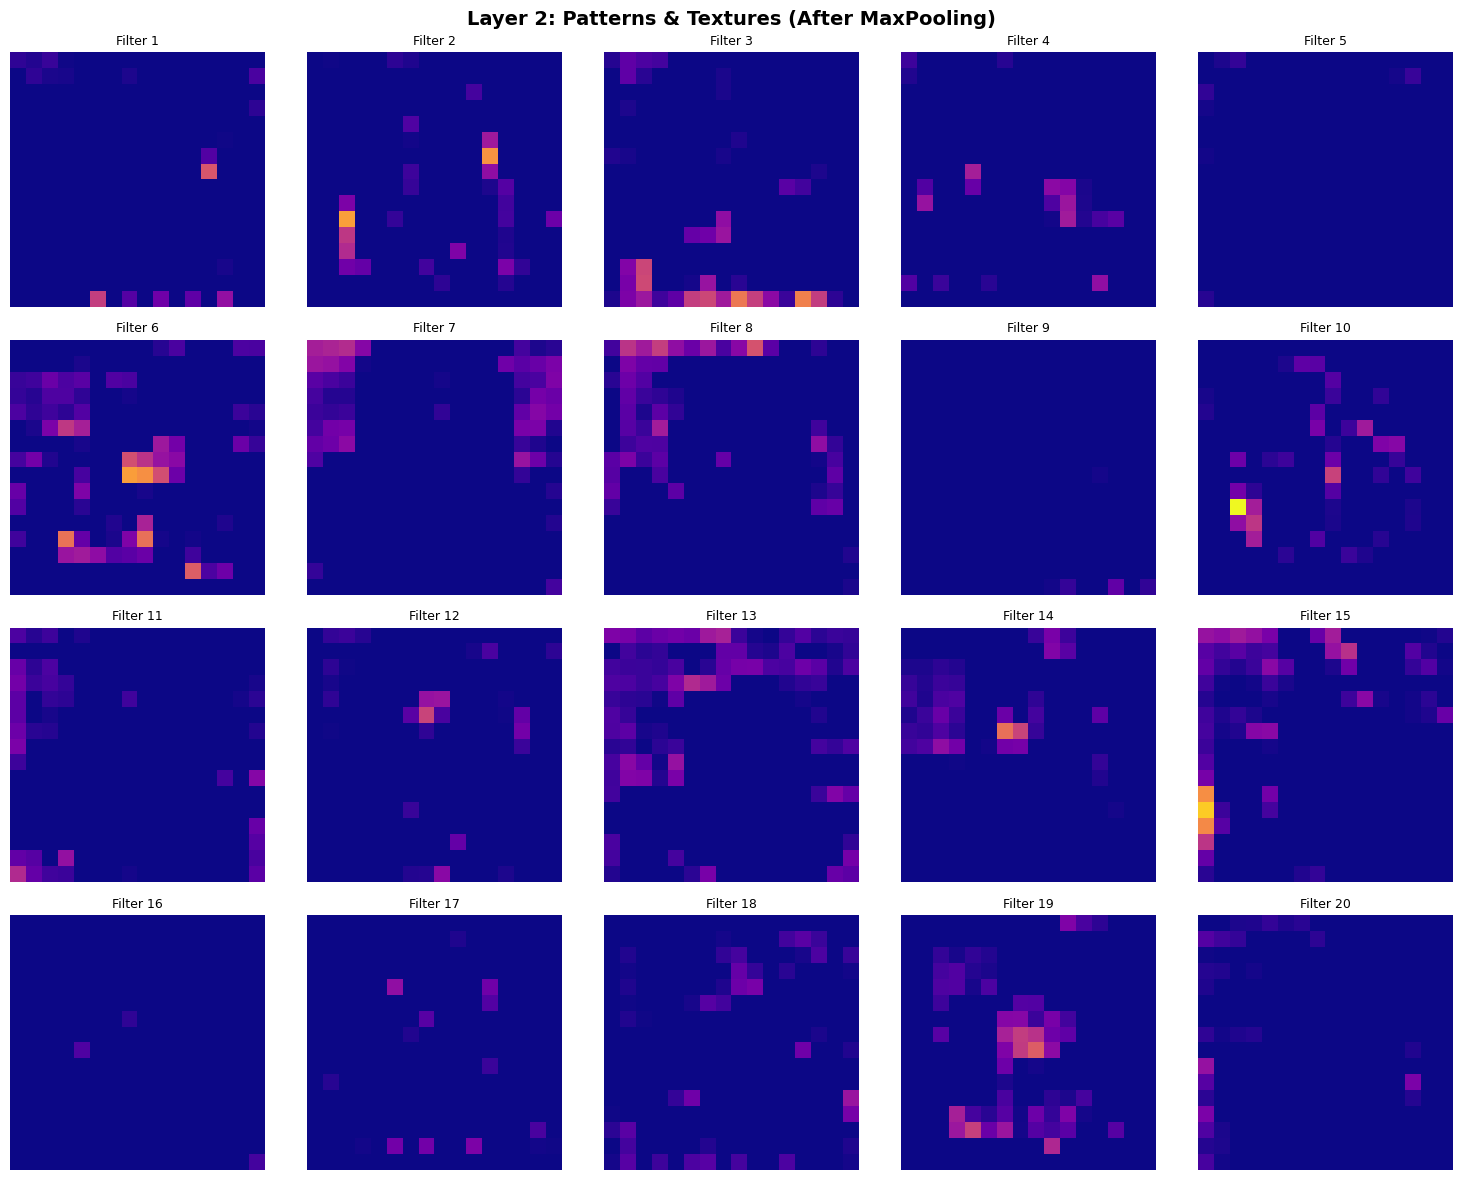


💡 WHAT TO OBSERVE:
  • Image is SMALLER (16×16) due to pooling
  • Filters detect MORE COMPLEX patterns
  • You can see TEXTURES forming
  • Some filters activate on SPECIFIC object parts
  • Patterns like 'fur', 'metal', 'wheels' emerge
  • Less like original image, more ABSTRACT

🎯 TRY THIS:
  • Compare Layer 1 and Layer 2 side by side
  • Notice how Layer 2 is MORE ABSTRACT
  • Try images of CATS vs DOGS - different patterns!
  • Try images of VEHICLES - look for wheel patterns!


In [10]:
print("🔬 Visualizing Layer 2: Patterns & Textures\n")

# Create model for layer 2
layer2_model = models.Model(
    inputs=model.inputs,   # .inputs, not .input (Keras 3)
    outputs=model.get_layer('conv2_1').output
)

# Get activations
layer2_output = layer2_model.predict(test_image, verbose=0)

print(f"Layer 2 output shape: {layer2_output.shape}")
print(f"  → 16×16 image (pooled), 64 different filters\n")

# Plot first 20 filters
fig, axes = plt.subplots(4, 5, figsize=(15, 12))
axes = axes.ravel()

vmax = layer2_output[0, :, :, :20].max()   # ONE colour scale for every map in this figure
for i in range(20):
    axes[i].imshow(layer2_output[0, :, :, i], cmap='plasma', vmin=0, vmax=vmax)
    axes[i].set_title(f"Filter {i+1}", fontsize=9)
    axes[i].axis('off')

plt.suptitle('Layer 2: Patterns & Textures (After MaxPooling)',
             fontsize=14, fontweight='bold')
plt.tight_layout()
plt.show()

print("\n💡 WHAT TO OBSERVE:")
print("  • Image is SMALLER (16×16) due to pooling")
print("  • Filters detect MORE COMPLEX patterns")
print("  • You can see TEXTURES forming")
print("  • Some filters activate on SPECIFIC object parts")
print("  • Patterns like 'fur', 'metal', 'wheels' emerge")
print("  • Less like original image, more ABSTRACT")

print("\n🎯 TRY THIS:")
print("  • Compare Layer 1 and Layer 2 side by side")
print("  • Notice how Layer 2 is MORE ABSTRACT")
print("  • Try images of CATS vs DOGS - different patterns!")
print("  • Try images of VEHICLES - look for wheel patterns!")

---
## 🔬 Cell 11: VISUALIZE LAYER 3 - Object Features!

**Layer 3 (conv3_1): High-Level Features**
- Learns: Complete object parts
- "Face", "Wing", "Wheel", "Body"
- 128 filters (most complex!)

🔬 Visualizing Layer 3: Object Features

Layer 3 output shape: (1, 8, 8, 128)
  → 8×8 image (pooled twice), 128 different filters



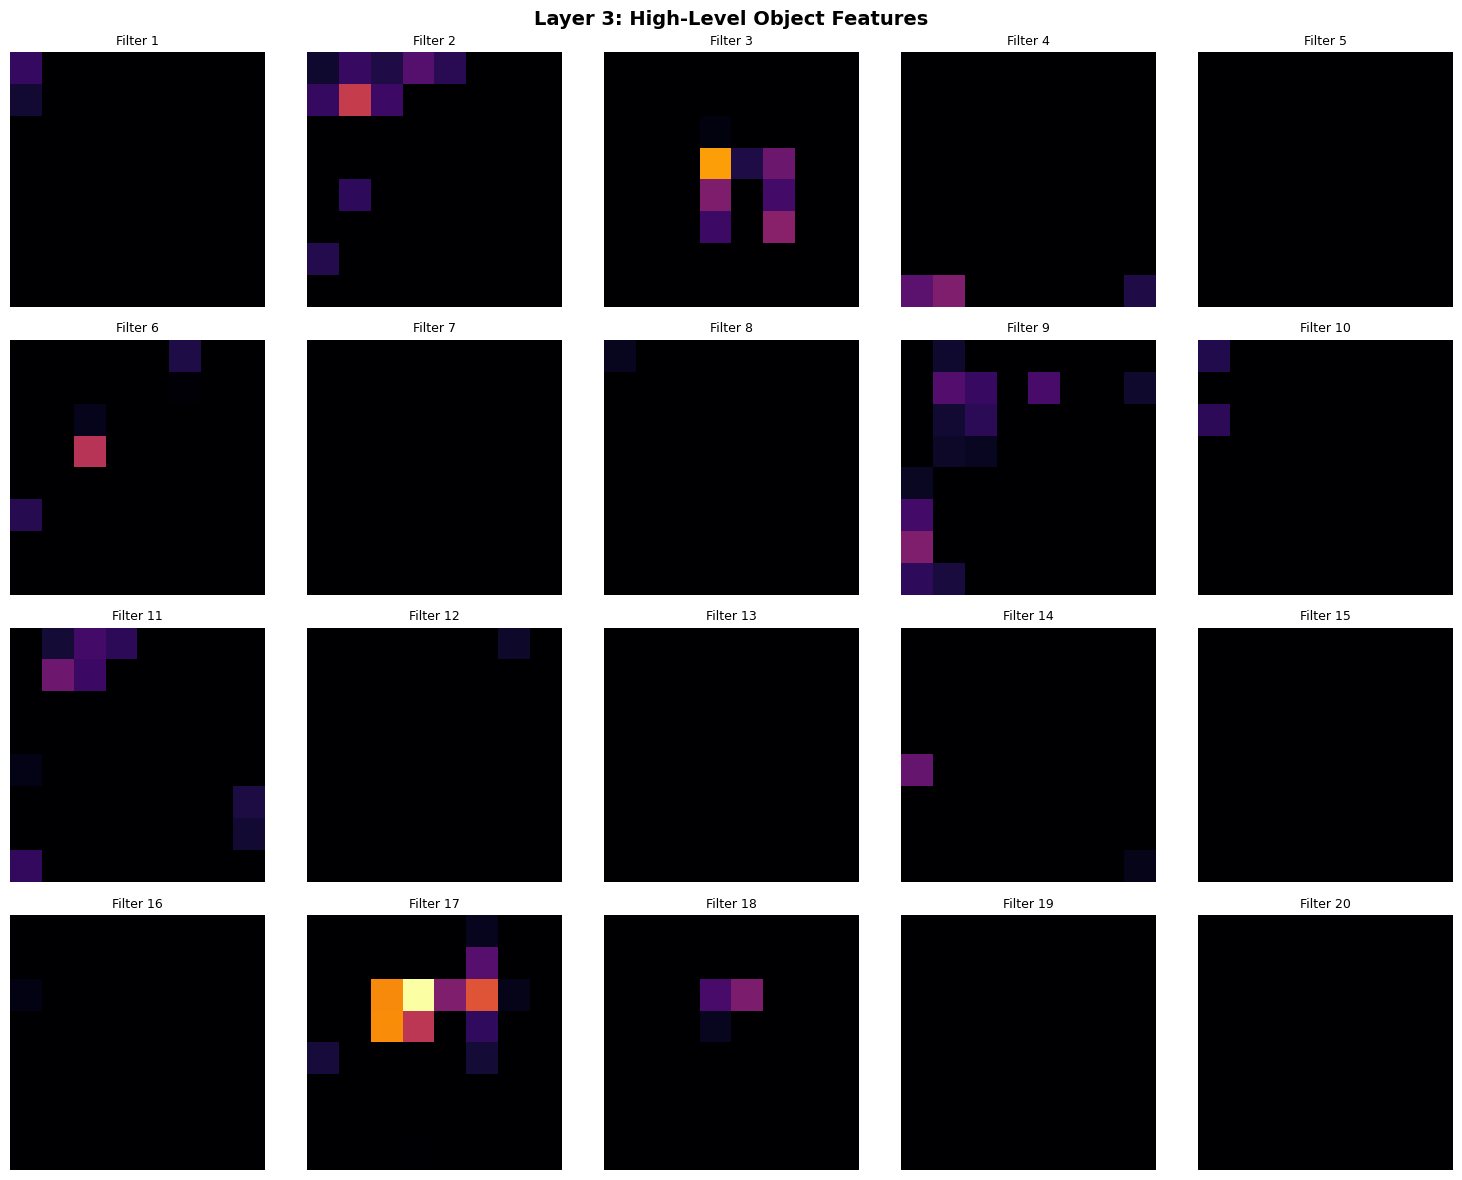


💡 WHAT TO OBSERVE:
  • Image is VERY SMALL (8×8)
  • Filters respond to LARGER, more object-like patterns
  • VERY ABSTRACT - hard to see original image
  • Some filters respond much more to some classes than to others
    (change test_idx to a cat, then a truck, and compare)
  • This is what the CNN 'understands'!

🎯 TRY THIS:
  • Try different object types
  • Animals (cat, dog, horse, bird, frog, deer)
  • Vehicles (car, truck, plane, ship)
  • Notice how DIFFERENT objects activate DIFFERENT filters
  • This is how CNN learns to tell them apart!


In [11]:
print("🔬 Visualizing Layer 3: Object Features\n")

# Create model for layer 3
layer3_model = models.Model(
    inputs=model.inputs,   # .inputs, not .input (Keras 3)
    outputs=model.get_layer('conv3_1').output
)

# Get activations
layer3_output = layer3_model.predict(test_image, verbose=0)

print(f"Layer 3 output shape: {layer3_output.shape}")
print(f"  → 8×8 image (pooled twice), 128 different filters\n")

# Plot first 20 filters
fig, axes = plt.subplots(4, 5, figsize=(15, 12))
axes = axes.ravel()

vmax = layer3_output[0, :, :, :20].max()   # ONE colour scale for every map in this figure
for i in range(20):
    axes[i].imshow(layer3_output[0, :, :, i], cmap='inferno', vmin=0, vmax=vmax)
    axes[i].set_title(f"Filter {i+1}", fontsize=9)
    axes[i].axis('off')

plt.suptitle('Layer 3: High-Level Object Features',
             fontsize=14, fontweight='bold')
plt.tight_layout()
plt.show()

print("\n💡 WHAT TO OBSERVE:")
print("  • Image is VERY SMALL (8×8)")
print("  • Filters respond to LARGER, more object-like patterns")
print("  • VERY ABSTRACT - hard to see original image")
print("  • Some filters respond much more to some classes than to others")
print("    (change test_idx to a cat, then a truck, and compare)")
print("  • This is what the CNN 'understands'!")

print("\n🎯 TRY THIS:")
print("  • Try different object types")
print("  • Animals (cat, dog, horse, bird, frog, deer)")
print("  • Vehicles (car, truck, plane, ship)")
print("  • Notice how DIFFERENT objects activate DIFFERENT filters")
print("  • This is how CNN learns to tell them apart!")

---
## 🔍 Cell 12: Compare All Layers Side-by-Side

See how the same image looks through each layer!

🔍 Comparing all layers for the same image



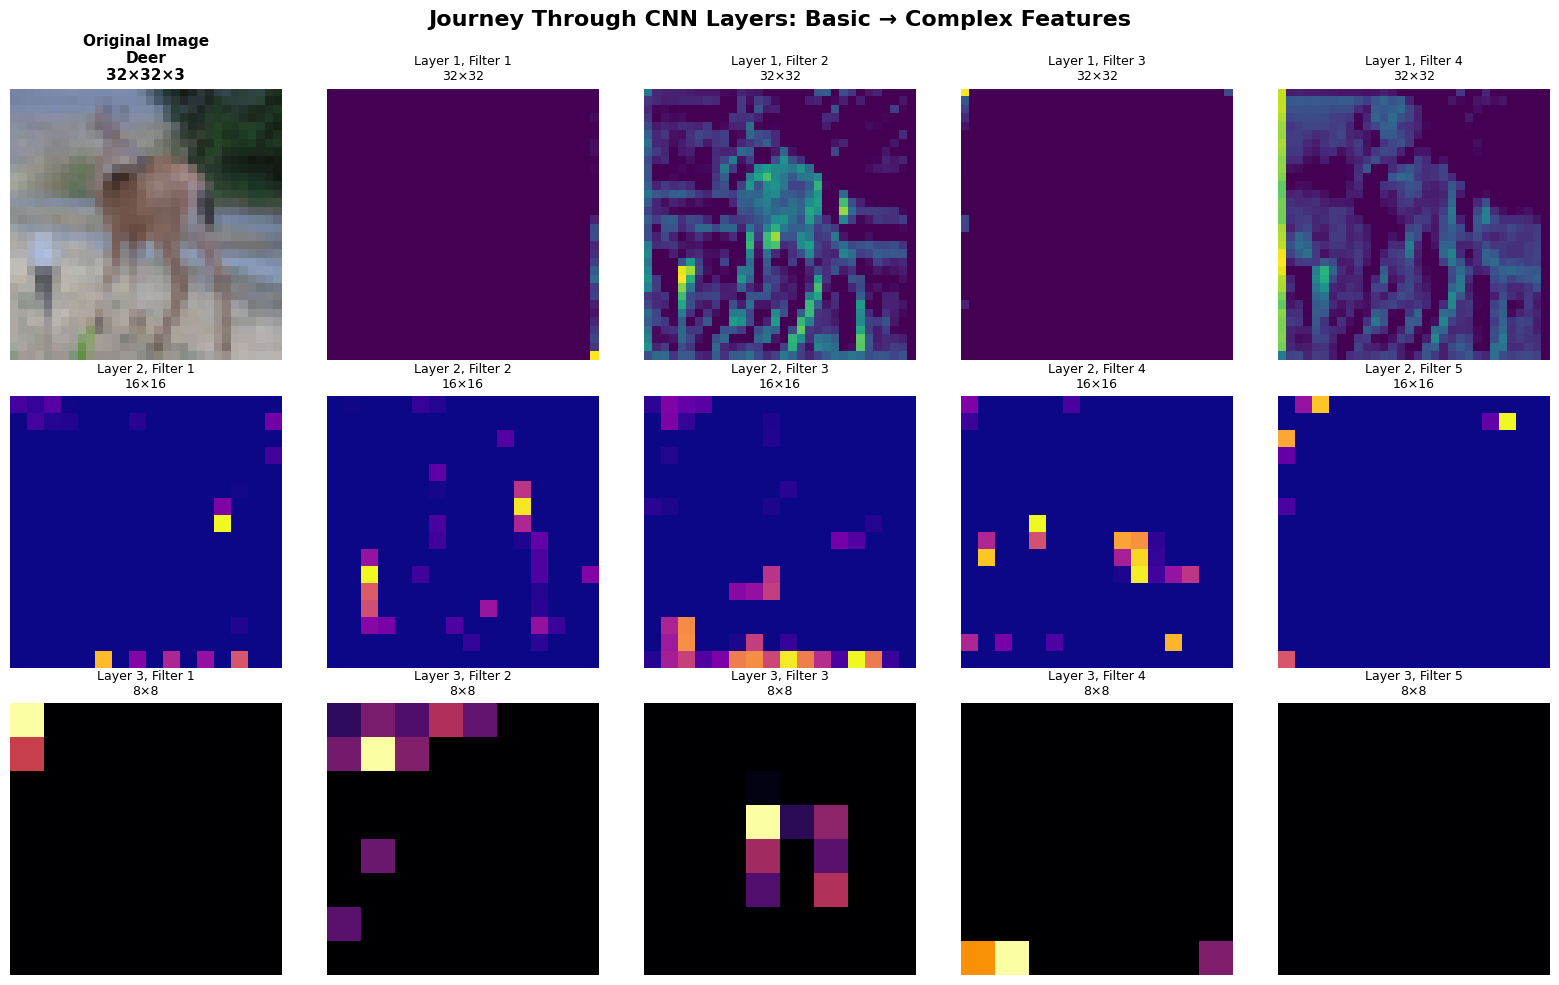


🎓 LEARNING SUMMARY:

  Layer 1 (32×32):
    • Detects EDGES (horizontal, vertical, diagonal)
    • Detects COLOR changes
    • Detects SIMPLE shapes (lines, curves)
    • Still looks like original image

  Layer 2 (16×16):
    • Combines edges into PATTERNS
    • Detects TEXTURES (fur, metal, feathers)
    • Detects SHAPES (circles, rectangles)
    • More abstract, less like original

  Layer 3 (8×8):
    • Responds to larger, object-like patterns
    • Different classes light up different filters
    • VERY abstract - the 'concept' of object
    • This is what CNN uses to classify!

💡 KEY INSIGHT:
  CNN builds understanding from SIMPLE → COMPLEX
  Like how humans learn: lines → shapes → objects!


In [12]:
print("🔍 Comparing all layers for the same image\n")

# Create figure
fig = plt.figure(figsize=(16, 10))

# Original image (large)
ax1 = plt.subplot(3, 5, 1)
ax1.imshow(X_test[test_idx])
ax1.set_title(f"Original Image\n{test_label}\n32×32×3",
              fontweight='bold', fontsize=11)
ax1.axis('off')

# Layer 1: First 4 filters
for i in range(4):
    ax = plt.subplot(3, 5, i+2)
    ax.imshow(layer1_output[0, :, :, i], cmap='viridis')
    ax.set_title(f"Layer 1, Filter {i+1}\n32×32", fontsize=9)
    ax.axis('off')

# Layer 2: First 5 filters
for i in range(5):
    ax = plt.subplot(3, 5, i+6)
    ax.imshow(layer2_output[0, :, :, i], cmap='plasma')
    ax.set_title(f"Layer 2, Filter {i+1}\n16×16", fontsize=9)
    ax.axis('off')

# Layer 3: First 5 filters
for i in range(5):
    ax = plt.subplot(3, 5, i+11)
    ax.imshow(layer3_output[0, :, :, i], cmap='inferno')
    ax.set_title(f"Layer 3, Filter {i+1}\n8×8", fontsize=9)
    ax.axis('off')

plt.suptitle('Journey Through CNN Layers: Basic → Complex Features',
             fontsize=16, fontweight='bold')
plt.tight_layout()
plt.show()

print("\n🎓 LEARNING SUMMARY:")
print("\n  Layer 1 (32×32):")
print("    • Detects EDGES (horizontal, vertical, diagonal)")
print("    • Detects COLOR changes")
print("    • Detects SIMPLE shapes (lines, curves)")
print("    • Still looks like original image")

print("\n  Layer 2 (16×16):")
print("    • Combines edges into PATTERNS")
print("    • Detects TEXTURES (fur, metal, feathers)")
print("    • Detects SHAPES (circles, rectangles)")
print("    • More abstract, less like original")

print("\n  Layer 3 (8×8):")
print("    • Responds to larger, object-like patterns")
print("    • Different classes light up different filters")
print("    • VERY abstract - the 'concept' of object")
print("    • This is what CNN uses to classify!")

print("\n💡 KEY INSIGHT:")
print("  CNN builds understanding from SIMPLE → COMPLEX")
print("  Like how humans learn: lines → shapes → objects!")

---
## 🎨 Cell 13: What Do Filters Look Like?

Let's see the actual filters the CNN learned!

🎨 Visualizing learned filters (weights)

Filter shape: (3, 3, 3, 32)
  → 3×3 kernel, 3 input channels (RGB), 32 output filters



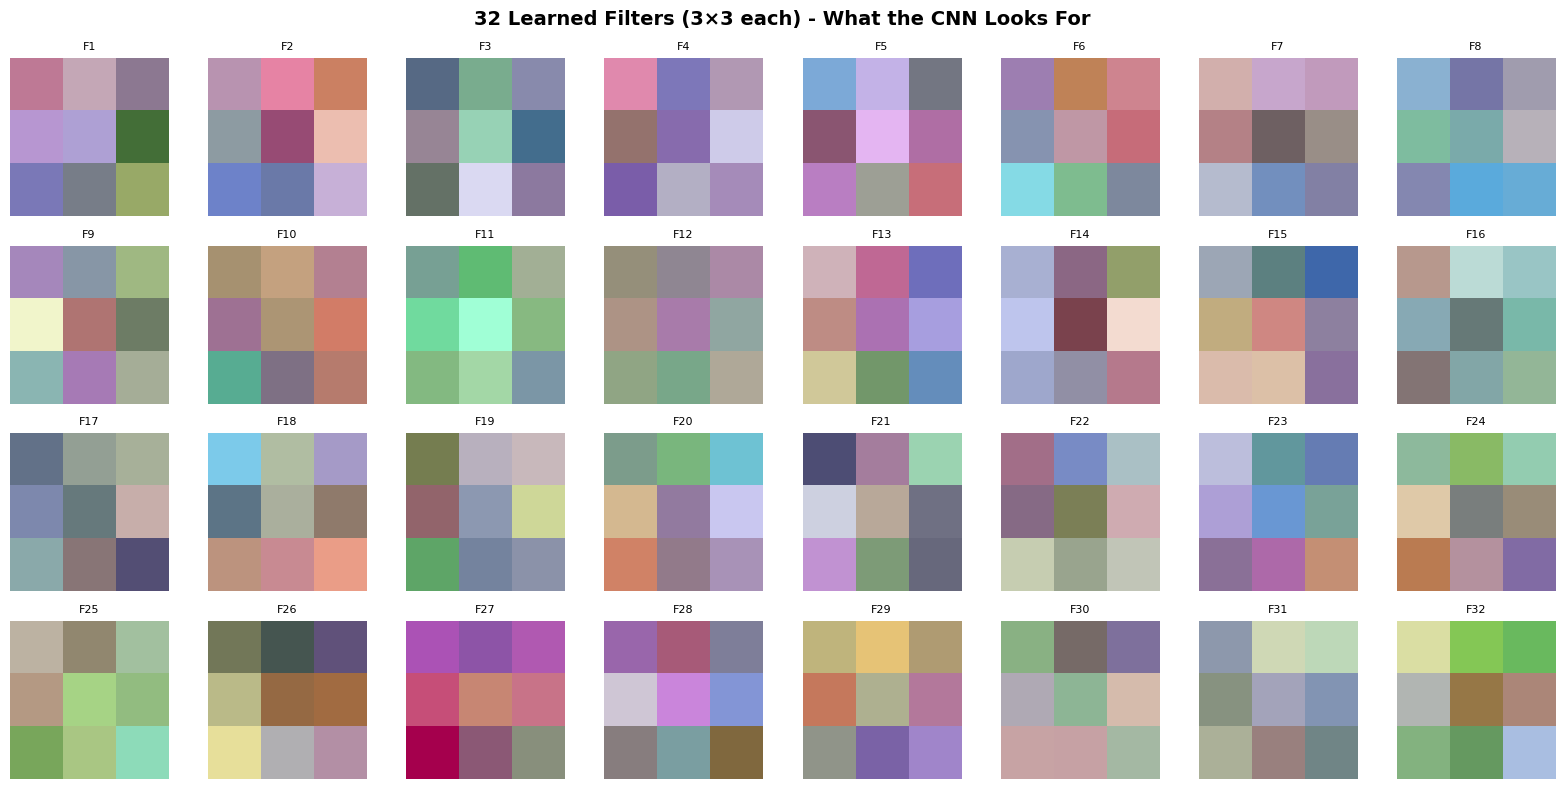


💡 WHAT TO OBSERVE:
  • Each 3×3 grid is a FILTER (kernel)
  • Colors show what pattern the filter detects
  • Some filters detect LIGHT/DARK transitions (edges)
  • Some filters detect COLOR patterns
  • Some filters detect DIAGONAL features
  • These tiny patterns combine to recognize objects!

🎯 EXPERIMENT:
  • Train the model again with different random seeds
  • The filters will look DIFFERENT but work similarly!
  • This shows CNN learns AUTOMATICALLY


In [13]:
print("🎨 Visualizing learned filters (weights)\n")

# Get first convolutional layer weights
filters, biases = model.get_layer('conv1_1').get_weights()

print(f"Filter shape: {filters.shape}")
print(f"  → 3×3 kernel, 3 input channels (RGB), 32 output filters\n")

# Normalize filters for visualization
f_min, f_max = filters.min(), filters.max()
filters_norm = (filters - f_min) / (f_max - f_min)

# Plot first 32 filters
fig, axes = plt.subplots(4, 8, figsize=(16, 8))
axes = axes.ravel()

for i in range(32):
    # Get filter (3×3×3)
    f = filters_norm[:, :, :, i]
    # Display as RGB
    axes[i].imshow(f)
    axes[i].set_title(f"F{i+1}", fontsize=8)
    axes[i].axis('off')

plt.suptitle('32 Learned Filters (3×3 each) - What the CNN Looks For',
             fontsize=14, fontweight='bold')
plt.tight_layout()
plt.show()

print("\n💡 WHAT TO OBSERVE:")
print("  • Each 3×3 grid is a FILTER (kernel)")
print("  • Colors show what pattern the filter detects")
print("  • Some filters detect LIGHT/DARK transitions (edges)")
print("  • Some filters detect COLOR patterns")
print("  • Some filters detect DIAGONAL features")
print("  • These tiny patterns combine to recognize objects!")

print("\n🎯 EXPERIMENT:")
print("  • Train the model again with different random seeds")
print("  • The filters will look DIFFERENT but work similarly!")
print("  • This shows CNN learns AUTOMATICALLY")

---
## 🎯 Cell 14: Evaluate Model

In [14]:
print("🎯 Evaluating model on test set...\n")

test_loss, test_accuracy = model.evaluate(X_test_norm, y_test_cat, verbose=0)

print("✅ Evaluation complete!\n")
print(f"📊 Test Results:")
print(f"  Test Accuracy: {test_accuracy*100:.2f}%")
print(f"  Test Loss: {test_loss:.4f}")
print(f"  Tested on: {len(X_test):,} images")

🎯 Evaluating model on test set...



✅ Evaluation complete!

📊 Test Results:
  Test Accuracy: 82.69%
  Test Loss: 0.6099
  Tested on: 10,000 images


---
## 🔍 Cell 15: Test on Random Images

🔍 Testing on random images...



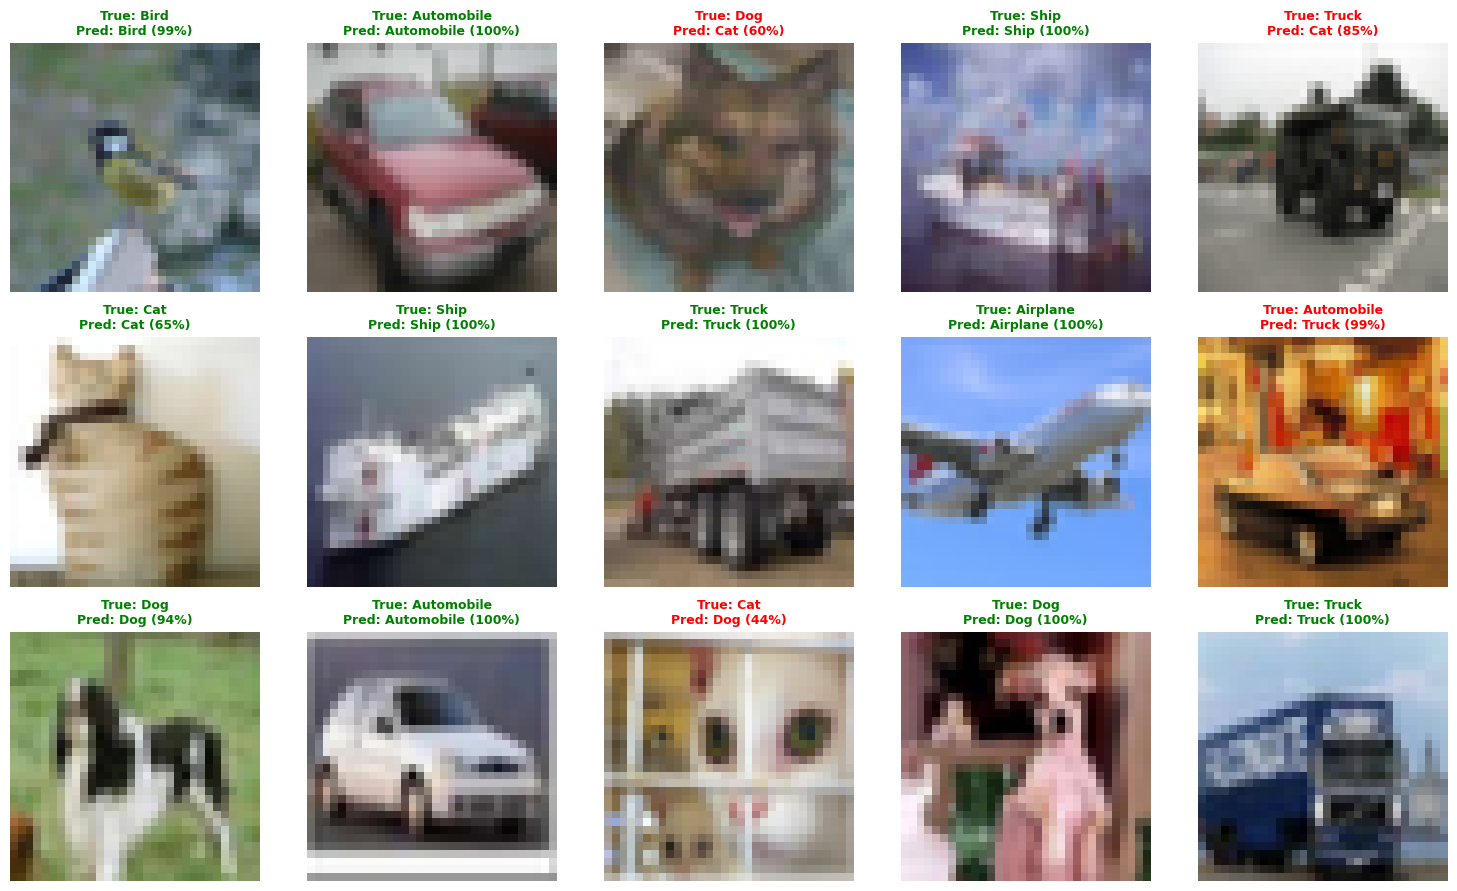


✅ Predictions complete!


In [15]:
print("🔍 Testing on random images...\n")

num_examples = 15
random_indices = np.random.choice(len(X_test), num_examples, replace=False)

fig, axes = plt.subplots(3, 5, figsize=(15, 9))
axes = axes.ravel()

for i, idx in enumerate(random_indices):
    # Predict
    img = X_test_norm[idx:idx+1]
    prediction = model.predict(img, verbose=0)
    predicted_class = np.argmax(prediction)
    true_class = y_test[idx][0]
    confidence = prediction[0][predicted_class] * 100

    # Display
    axes[i].imshow(X_test[idx])
    color = 'green' if predicted_class == true_class else 'red'

    axes[i].set_title(
        f"True: {class_names[true_class]}\n"
        f"Pred: {class_names[predicted_class]} ({confidence:.0f}%)",
        fontsize=9,
        color=color,
        fontweight='bold'
    )
    axes[i].axis('off')

plt.tight_layout()
plt.show()

print(f"\n✅ Predictions complete!")

---
## 📤 Cell 16: Upload YOUR Photo!

**Photo Tips:**
1. Clear, focused images
2. Object fills the frame
3. Good lighting
4. Try: toy cars, stuffed animals, pets, outdoor scenes
5. Photos work best: drawings look nothing like the photos it learned from, so expect surprises

In [16]:
print("📤 Upload your photo!\n")
print("💡 Tips:")
print("  • Clear, focused image")
print("  • Object fills frame")
print("  • Good lighting")
print("  • Try toys, pets, vehicles!\n")

# Where does the photo come from?
#  • In Google Colab: an upload button appears (cancel it to use the demo photo instead).
#  • In Jupyter / VS Code: put your own file names in MY_IMAGES below.
#  • With neither, the notebook makes a demo "photo" (a test image enlarged to 256×256) so every cell still runs.
try:
    from google.colab import files
    IN_COLAB = True
except ImportError:
    IN_COLAB = False

MY_IMAGES = []      # e.g. ["my_cat.jpg"]  (used when not in Colab)


def make_demo_photo(test_index=3, path='demo_photo.png'):
    """Enlarge one CIFAR-10 TEST image to 256×256 and save it, standing in for a photo you took."""
    from PIL import Image as _PILImage
    _PILImage.fromarray(X_test[test_index]).resize((256, 256), _PILImage.Resampling.BICUBIC).save(path)
    print(f"(Demo photo: test image #{test_index}, a {class_names[y_test[test_index][0]]}, enlarged to 256×256.)")
    return path


def get_images():
    """Return a list of image file names to classify."""
    if IN_COLAB:
        uploaded = files.upload()
        if uploaded:
            return list(uploaded.keys())
    if MY_IMAGES:
        return list(MY_IMAGES)
    print("(No upload, so using a demo photo. Add your own file names to MY_IMAGES, or run this in Colab to upload.)")
    return [make_demo_photo()]


def center_crop_square(pil_img):
    """Cut the largest centred square out of a photo. CIFAR-10 images are square and the object fills them;
    squashing a 4:3 photo straight to 32×32 would stretch everything sideways."""
    w, h = pil_img.size
    s = min(w, h)
    left, top = (w - s) // 2, (h - s) // 2
    return pil_img.crop((left, top, left + s, top + s))

uploaded = get_images()
print("\n✅ Image ready:", uploaded[0])

📤 Upload your photo!

💡 Tips:
  • Clear, focused image
  • Object fills frame
  • Good lighting
  • Try toys, pets, vehicles!

(No upload, so using a demo photo. Add your own file names to MY_IMAGES, or run this in Colab to upload.)
(Demo photo: test image #3, a Airplane, enlarged to 256×256.)

✅ Image ready: demo_photo.png


---
## 🔍 Cell 17: Preprocess & Classify YOUR Photo


🔍 Processing: demo_photo.png

📸 Original size: (256, 256)


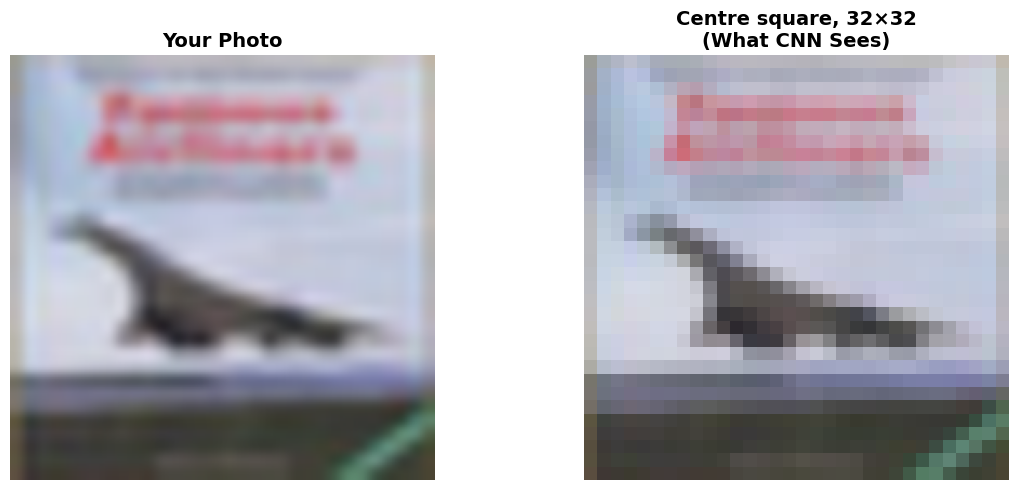


✅ Ready for classification!


In [17]:
def preprocess_uploaded_image(filename):
    """Preprocess uploaded image for CIFAR-10"""
    img = cv2.imread(filename)
    if img is None:
        print("❌ Could not read image!")
        return None, None

    # Convert BGR to RGB
    img_rgb = cv2.cvtColor(img, cv2.COLOR_BGR2RGB)
    print(f"📸 Original size: {img_rgb.shape[:2]}")

    # Crop the centre square (CIFAR-10 images are square), then shrink to 32×32
    from PIL import Image
    square = np.array(center_crop_square(Image.fromarray(img_rgb)))
    resized = cv2.resize(square, (32, 32), interpolation=cv2.INTER_AREA)

    # Normalize
    normalized = resized.astype('float32') / 255.0

    # Reshape for model
    final = normalized.reshape(1, 32, 32, 3)

    return img_rgb, final

# Process
filename = uploaded[0]
print(f"\n🔍 Processing: {filename}\n")

original, processed = preprocess_uploaded_image(filename)

if processed is not None:
    fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(12, 5))

    ax1.imshow(original)
    ax1.set_title('Your Photo', fontsize=14, fontweight='bold')
    ax1.axis('off')

    ax2.imshow(processed[0])
    ax2.set_title('Centre square, 32×32\n(What CNN Sees)', fontsize=14, fontweight='bold')
    ax2.axis('off')

    plt.tight_layout()
    plt.show()

    print("\n✅ Ready for classification!")

---
## 🎯 Cell 18: AI Classification Result!

🤖 Classifying your photo...



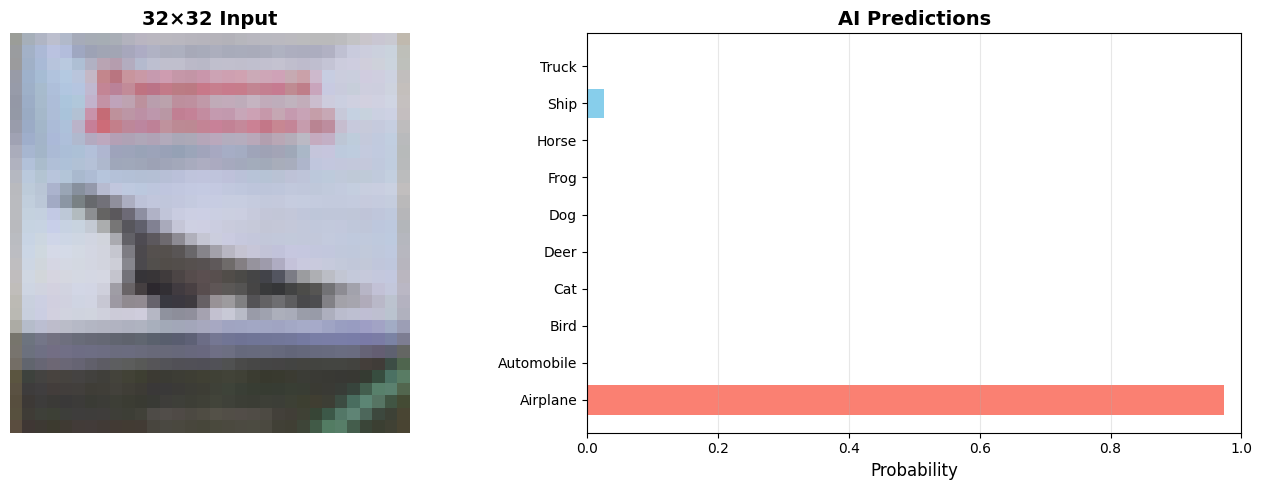


🎯 AI CLASSIFICATION RESULT

  🏆 Prediction: ✈️ AIRPLANE
  📊 Confidence: 97.36%

  📈 Top 3:
    🥇 ✈️ Airplane: 97.36%
    🥈 🚢 Ship: 2.60%
    🥉 🚚 Truck: 0.04%


💪 Very confident!


In [18]:
if processed is not None:
    print("🤖 Classifying your photo...\n")

    # Predict
    prediction = model.predict(processed, verbose=0)
    predicted_class = np.argmax(prediction)
    confidence = prediction[0][predicted_class] * 100

    # Visualize
    fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(14, 5))

    ax1.imshow(processed[0])
    ax1.set_title('32×32 Input', fontsize=14, fontweight='bold')
    ax1.axis('off')

    colors = ['salmon' if i == predicted_class else 'skyblue'
              for i in range(10)]
    ax2.barh(range(10), prediction[0], color=colors)
    ax2.set_yticks(range(10))
    ax2.set_yticklabels([f"{class_names[i]}"
                          for i in range(10)])
    ax2.set_xlabel('Probability', fontsize=12)
    ax2.set_title('AI Predictions', fontsize=14, fontweight='bold')
    ax2.set_xlim([0, 1])
    ax2.grid(axis='x', alpha=0.3)

    plt.tight_layout()
    plt.show()

    # Results
    print("\n" + "="*60)
    print("🎯 AI CLASSIFICATION RESULT")
    print("="*60)
    print(f"\n  🏆 Prediction: {class_emojis[predicted_class]} {class_names[predicted_class].upper()}")
    print(f"  📊 Confidence: {confidence:.2f}%")

    print(f"\n  📈 Top 3:")
    top_3 = np.argsort(prediction[0])[-3:][::-1]
    medals = ["🥇", "🥈", "🥉"]
    for rank, cls in enumerate(top_3):
        print(f"    {medals[rank]} {class_emojis[cls]} {class_names[cls]}: "
              f"{prediction[0][cls]*100:.2f}%")

    print("\n" + "="*60)

    if confidence >= 80:
        print("\n💪 Very confident!")
    elif confidence >= 60:
        print("\n👍 Good confidence!")
    else:
        print("\n🤔 Uncertain - try clearer photo!")

---
## 🔬 Cell 19: See YOUR Photo Through CNN Layers!

Watch how the CNN processes YOUR uploaded image!

🔬 Visualizing YOUR image through CNN layers



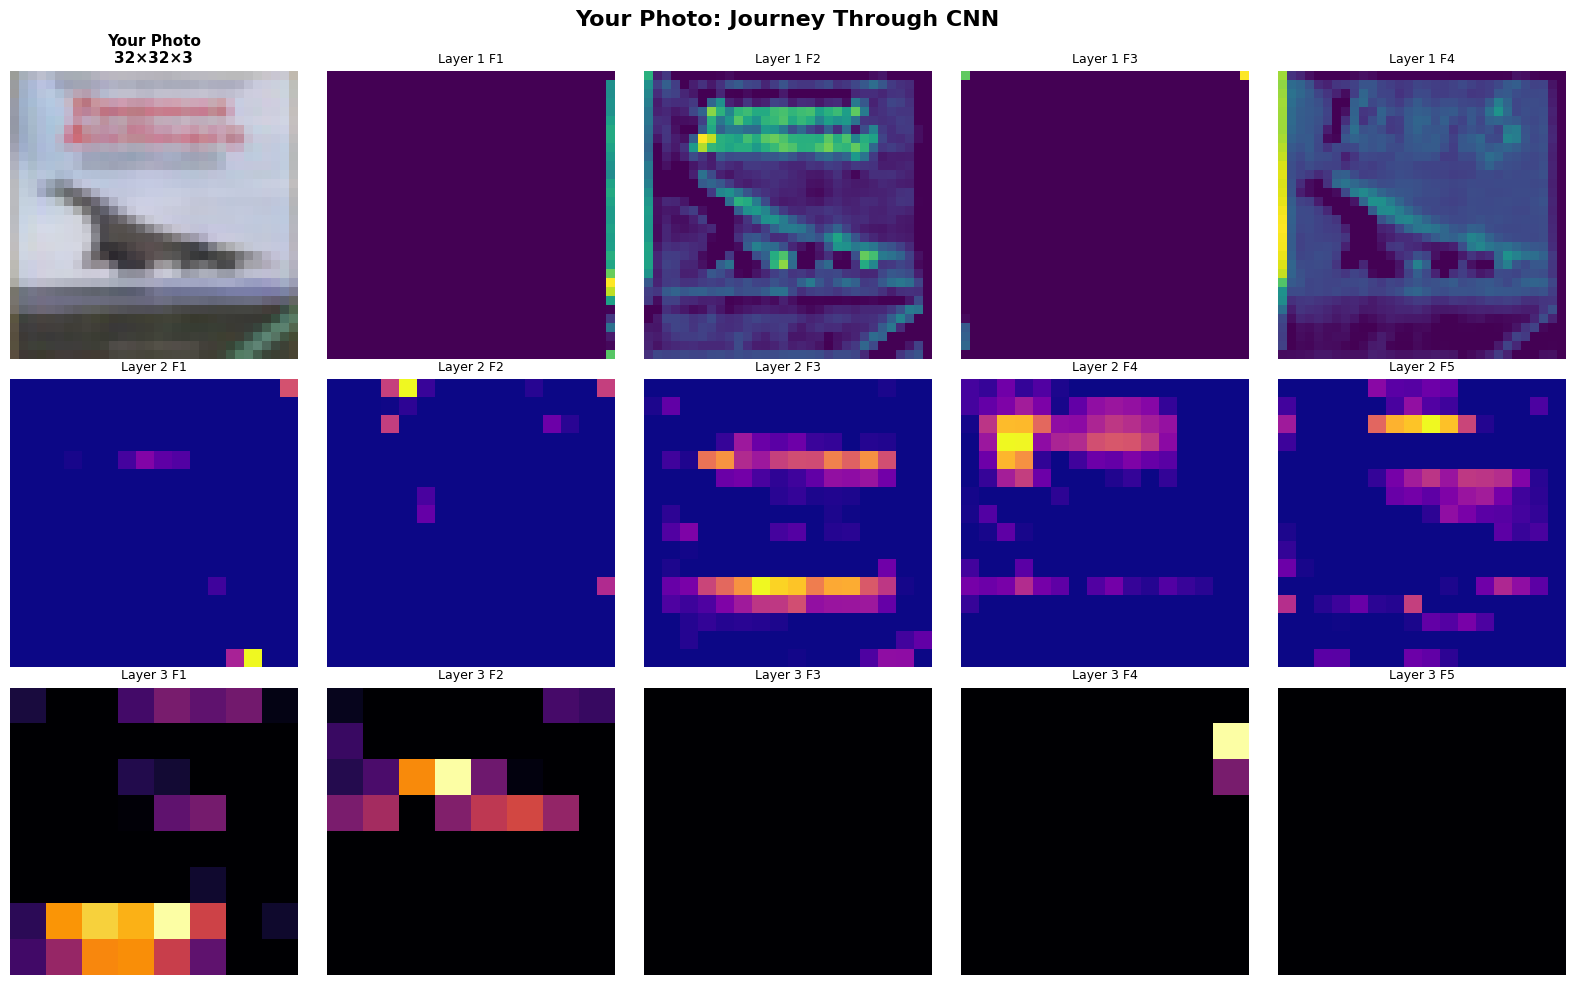


💡 WHAT YOU'RE SEEING:
  • Layer 1: CNN finds edges and colors in YOUR photo
  • Layer 2: CNN identifies patterns and textures
  • Layer 3: CNN recognizes object features
  • Final layer uses these to classify!

🎯 EXPERIMENT:
  • Upload DIFFERENT objects
  • Compare how layers respond
  • Animals activate different filters than vehicles!


In [19]:
if processed is not None:
    print("🔬 Visualizing YOUR image through CNN layers\n")

    # Get activations for all layers
    user_layer1 = layer1_model.predict(processed, verbose=0)
    user_layer2 = layer2_model.predict(processed, verbose=0)
    user_layer3 = layer3_model.predict(processed, verbose=0)

    # Create comparison
    fig = plt.figure(figsize=(16, 10))

    # Original
    ax1 = plt.subplot(3, 5, 1)
    ax1.imshow(processed[0])
    ax1.set_title("Your Photo\n32×32×3", fontweight='bold', fontsize=11)
    ax1.axis('off')

    # Layer 1
    for i in range(4):
        ax = plt.subplot(3, 5, i+2)
        ax.imshow(user_layer1[0, :, :, i], cmap='viridis')
        ax.set_title(f"Layer 1 F{i+1}", fontsize=9)
        ax.axis('off')

    # Layer 2
    for i in range(5):
        ax = plt.subplot(3, 5, i+6)
        ax.imshow(user_layer2[0, :, :, i], cmap='plasma')
        ax.set_title(f"Layer 2 F{i+1}", fontsize=9)
        ax.axis('off')

    # Layer 3
    for i in range(5):
        ax = plt.subplot(3, 5, i+11)
        ax.imshow(user_layer3[0, :, :, i], cmap='inferno')
        ax.set_title(f"Layer 3 F{i+1}", fontsize=9)
        ax.axis('off')

    plt.suptitle('Your Photo: Journey Through CNN',
                 fontsize=16, fontweight='bold')
    plt.tight_layout()
    plt.show()

    print("\n💡 WHAT YOU'RE SEEING:")
    print("  • Layer 1: CNN finds edges and colors in YOUR photo")
    print("  • Layer 2: CNN identifies patterns and textures")
    print("  • Layer 3: CNN recognizes object features")
    print("  • Final layer uses these to classify!")

    print("\n🎯 EXPERIMENT:")
    print("  • Upload DIFFERENT objects")
    print("  • Compare how layers respond")
    print("  • Animals activate different filters than vehicles!")
else:
    print("⚠️ Please upload an image first!")

---
## 🎓 Cell 20: Project Summary & Key Learnings

In [20]:
print(f"\n{'='*60}")
print("🎓 PROJECT COMPLETE!")
print(f"{'='*60}")

print("\n🧠 WHAT WE LEARNED:")
print("  • Built CNN for CIFAR-10 (10 colorful objects)")
print("  • VISUALIZED what each layer learns")
print("  • Saw filters detect edges → patterns → objects")
print("  • Classified YOUR uploaded photos!")
print("  • Watched YOUR photo flow through CNN layers")

print("\n📊 PERFORMANCE:")
print(f"  Test Accuracy: {test_accuracy*100:.2f}%")
print(f"  10 Categories: Animals + Vehicles")
print(f"  Trained on: 40,000 images (+10,000 held out for validation)")
print(f"  Tested on: 10,000 images")

print("\n🔬 KEY INSIGHTS:")
print("\n  1. LAYER 1 - Basic Features (32×32):")
print("     • Detects edges (horizontal, vertical, diagonal)")
print("     • Detects color transitions")
print("     • Like finding puzzle pieces")

print("\n  2. LAYER 2 - Patterns (16×16):")
print("     • Combines edges into shapes")
print("     • Detects textures (fur, metal, feathers)")
print("     • Like assembling puzzle sections")

print("\n  3. LAYER 3 - Objects (8×8):")
print("     • Responds to larger, object-like patterns")
print("     • Different classes light up different filters")
print("     • Like seeing the complete puzzle picture")

print("\n💡 HOW CNN LEARNS:")
print("  Simple → Complex → Abstract")
print("  Lines → Shapes → Objects")
print("  Just like how humans learn!")

print("\n🎯 THINGS TO TRY:")
print("  1. Upload different object types")
print("  2. Compare layer activations for animals vs vehicles")
print("  3. Try unclear/blurry photos - see how CNN struggles")
print("  4. Take photos at different angles")
print("  5. Try drawings vs real photos")
print("  6. Photograph toys and test them!")

print("\n🚀 NEXT STEPS:")
print("  • Try CIFAR-100 (100 classes!)")
print("  • Experiment with deeper CNNs")
print("  • Try transfer learning (ResNet, VGG)")
print("  • Build object detection (find objects in images)")
print("  • Try other datasets (Food-101, Flowers)")
print("  • Create mobile apps!")

print(f"\n{'='*60}")
print("✨ You now understand how CNNs SEE the world! ✨")
print(f"{'='*60}")


🎓 PROJECT COMPLETE!

🧠 WHAT WE LEARNED:
  • Built CNN for CIFAR-10 (10 colorful objects)
  • VISUALIZED what each layer learns
  • Saw filters detect edges → patterns → objects
  • Classified YOUR uploaded photos!
  • Watched YOUR photo flow through CNN layers

📊 PERFORMANCE:
  Test Accuracy: 82.69%
  10 Categories: Animals + Vehicles
  Trained on: 40,000 images (+10,000 held out for validation)
  Tested on: 10,000 images

🔬 KEY INSIGHTS:

  1. LAYER 1 - Basic Features (32×32):
     • Detects edges (horizontal, vertical, diagonal)
     • Detects color transitions
     • Like finding puzzle pieces

  2. LAYER 2 - Patterns (16×16):
     • Combines edges into shapes
     • Detects textures (fur, metal, feathers)
     • Like assembling puzzle sections

  3. LAYER 3 - Objects (8×8):
     • Responds to larger, object-like patterns
     • Different classes light up different filters
     • Like seeing the complete puzzle picture

💡 HOW CNN LEARNS:
  Simple → Complex → Abstract
  Lines → Shap

---
## 🧪 BONUS: Experiments to Try!

### Experiment 1: Compare Different Objects
- Upload photos of CATS and DOGS
- Look at Layer 3 activations
- Notice different filters activate!

### Experiment 2: Test Edge Cases
- Upload unclear/blurry photos
- Watch confidence drop
- See which layers struggle

### Experiment 3: Drawing vs Photo
- Upload a drawing of a car
- Upload a real car photo
- Compare layer responses

### Experiment 4: Angle Matters
- Take same object from different angles
- See how predictions change
- Learn about CNN limitations!

### Experiment 5: Background Effects
- Photo with simple background
- Photo with complex background
- See how CNN focuses on object

### Experiment 6: Color Importance
- Try black & white photos
- Compare with color photos
- See if CNN depends on color

**Have fun exploring! 🎉**